In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pandas as pd
from matplotlib.lines import lineStyles
from scipy import stats
from uncertainties import ufloat, UFloat
import uncertainties.umath as unc
from exp_phys_modules import exp_phys_misc as em
import handcalcs.render

### Measurements

In [2]:
# Measurements
R_L = ufloat(109.4, 0.012 * 109.4)
L = ufloat(1.044, 0.05 * 1.044 + 0.020)  # (5% + 20dgt)
C = ufloat(10.07e-6, 0.02 * 10.07e-6 + 0.01e-6)  # (2% + 1dgt)
R_fg = ufloat(50, 0.005 * 50)  # (0.5% sd)
R_res1 = ufloat(1133, 0.005 * 1133)
R_res2 = ufloat(485, 0.005 * 485)
R_res3 = ufloat(20, 0.005 * 20)

V_0 = 3.86
R_calc = 2 * unc.sqrt(L / C)
R_res2_calc = R_calc - R_L - R_fg
R_res1_calc = 2 * R_calc - R_L - R_fg

R1 = R_res1 + R_L + R_fg
R2 = R_res2 + R_L + R_fg
R3 = R_res3 + R_L + R_fg
sample_rate = 3000.0
# dt = 1 / sample_rate

freq_exp = 45.53  # Hz
freq_theo = (1 / (2 * np.pi)) * unc.sqrt(1 / (L * C))
freq_calc = (1 / (2 * np.pi)) * unc.sqrt((1 / (L * C)) - (R3 / (2 * L)) ** 2)  # included R

print(f'freq_exp: {freq_exp}, freq_theo: {freq_theo}, freq_calc: {freq_calc}')

# Create LateX table of measurements
df = pd.DataFrame([
    # headings
    {
        "{Quantity}": name,
        "{Reading}": val.n,
        "{Uncertainty}": val.s,
        "{units}": units
    }
    for name, val, units in [
        ("R_L, Inductor resistance", R_L, rf"$\Omega$"),
        ("L, Inductance", L, "H"),
        ("C, Capacitance", C, "F"),
        ("R_{FG}, function generator resistance", R_fg, rf"$\Omega$"),
    ]
])
print(df.to_latex(index=False, position="H", caption="Experimental Parameters"))


freq_exp: 45.53, freq_theo: 49.1+/-1.8, freq_calc: 47.1+/-1.6
\begin{table}[H]
\caption{Experimental Parameters}
\begin{tabular}{lrrl}
\toprule
{Quantity} & {Reading} & {Uncertainty} & {units} \\
\midrule
R_L, Inductor resistance & 109.400000 & 1.312800 & $\Omega$ \\
L, Inductance & 1.044000 & 0.072200 & H \\
C, Capacitance & 0.000010 & 0.000000 & F \\
R_{FG}, function generator resistance & 50.000000 & 0.250000 & $\Omega$ \\
\bottomrule
\end{tabular}
\end{table}



C:\Users\leste\Documents\repos\phys-bsc\.venv\Lib\site-packages\uncertainties\core.py:526: FutureWarning: AffineScalarFunc.error_components() is currently an instance method. This method is deprecated. In a future release it will be replaced with an instance property by the same name. It will be accessed by AffineScalarFunc.error_components (with no parentheses).
  return float(sqrt(sum(delta**2 for delta in self.error_components().values())))
C:\Users\leste\Documents\repos\phys-bsc\.venv\Lib\site-packages\uncertainties\core.py:491: FutureWarning: AffineScalarFunc.derivatives() is deprecated. It will be removed in a future release.
  for variable, derivative in self.derivatives.items():
C:\Users\leste\Documents\repos\phys-bsc\.venv\Lib\site-packages\uncertainties\core.py:526: FutureWarning: Variable.error_components() is currently an instance method. This method is deprecated. In a future release it will be replaced with an instance property by the same name. It will be accessed by Var

### Analysis of data

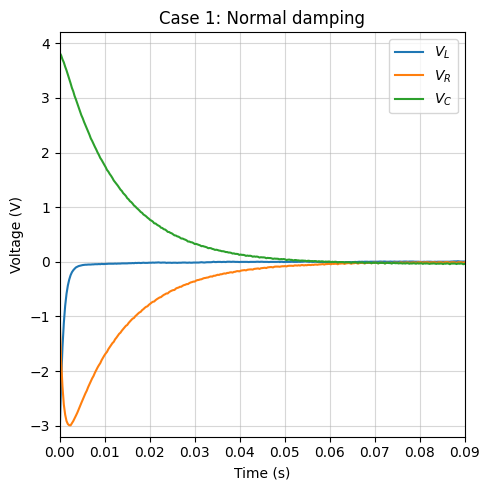

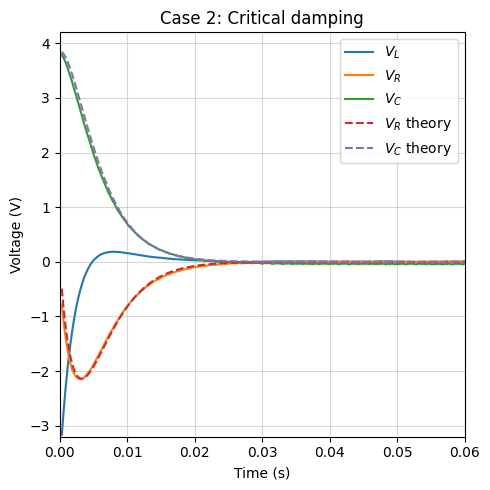

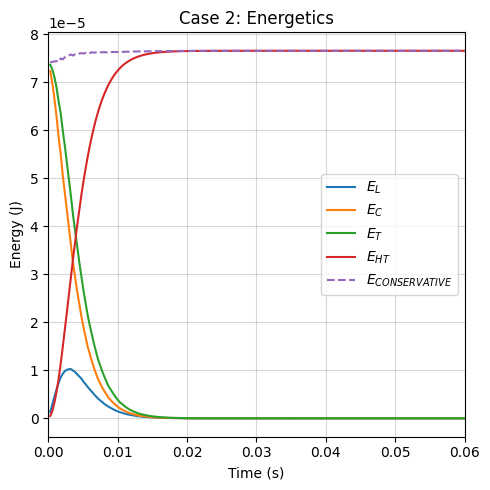

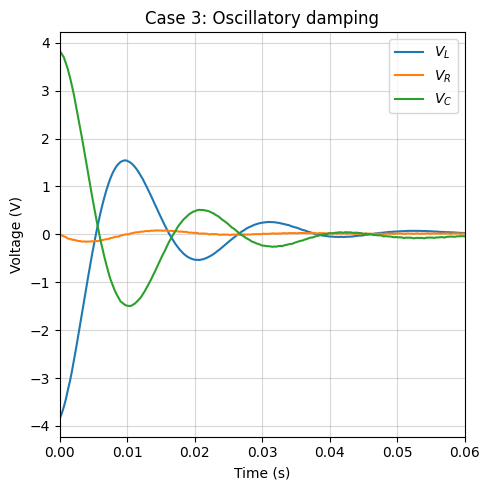

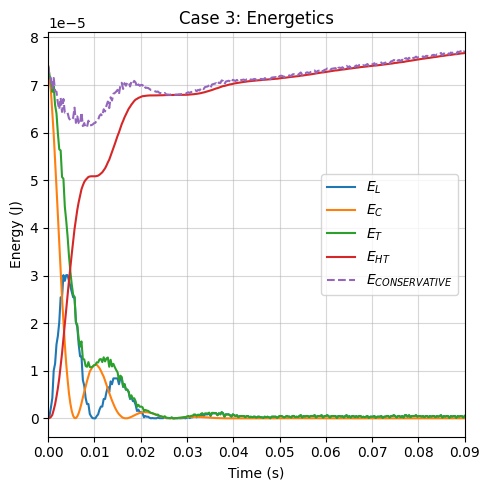

In [3]:
# Read data from Excel file
case1 = pl.read_csv("data/case1.csv")
case2 = pl.read_csv("data/case2.csv")
case3 = pl.read_csv("data/case3.csv")

# process data


# numpy array
t1 = case1["Time"].to_numpy()
t2 = case2["Time"].to_numpy()
t3 = case3["Time"].to_numpy()

dt = t1[1] - t1[0]

V_L1 = case1["V_L"].to_numpy()
V_R1 = case1["V_R"].to_numpy()
V_C1 = case1["V_C"].to_numpy()

V_L2 = case2["V_L"].to_numpy()
V_R2 = case2["V_R"].to_numpy()
V_C2 = case2["V_C"].to_numpy()

V_L3 = case3["V_L"].to_numpy()
V_R3 = case3["V_R"].to_numpy()
V_C3 = case3["V_C"].to_numpy()

# Numpy processing

# current
# i_theo = (-V_0 / L.n) * pl.col("Time") * np.exp(-R_calc.n * pl.col("Time") / (2 * L.n))
# i_exp2 = (V_R2 / R_res2.n)
# i_exp3 = (V_R3 / R_res3.n)

i_av2 = V_R2 / R_res2.n
i_av3 = V_R3 / R_res3.n

# theoretical calcs
V_R_theo2 = (-V_0 / L.n) * t2 * np.exp(-R2.n * t2 / (2 * L.n)) * R_res2.n
V_C_theo2 = V_0 * (1 + 2 * t2 / (R2.n * C.n)) * np.exp(-R2.n * t2 / (2 * L.n))

E_L2 = 0.5 * L.n * (i_av2 ** 2)
E_L3 = 0.5 * L.n * (i_av3 ** 2)

E_C2 = 0.5 * C.n * V_C2 ** 2
E_C3 = 0.5 * C.n * V_C3 ** 2

# sum C and L energies
E_T2 = E_L2 + E_C2
E_T3 = E_L3 + E_C3

E_H2 = R2.n * i_av2 ** 2 * dt  # heat energy dissipated
E_H3 = R3.n * i_av3 ** 2 * dt

# running sum
E_HT2 = np.cumsum(E_H2)
E_HT3 = np.cumsum(E_H3)

E_CON2 = E_T2 + E_HT2
E_CON3 = E_T3 + E_HT3

# plot data

# plot
plt.figure(figsize=(5, 5))
plt.title("Case 1: Normal damping")
plt.xlabel(r"Time (s)")
plt.ylabel(r"Voltage (V)")
plt.xlim(0, 0.09)
plt.ylim(-3.2, 4.2)
plt.plot(t1, V_L1, label=rf"$V_L$")
plt.plot(t1, V_R1, label=rf"$V_R$")
plt.plot(t1, V_C1, label=rf"$V_C$")
plt.legend(loc="best")
plt.grid(True, alpha=0.5)
plt.tight_layout()
# plt.savefig("fig/case1_normal_damping.png")
# plt.show()

plt.figure(figsize=(5, 5))
plt.title("Case 2: Critical damping")
plt.xlabel(r"Time (s)")
plt.ylabel(r"Voltage (V)")
plt.xlim(0, 0.06)
plt.ylim(-3.2, 4.2)
plt.plot(t2, V_L2, label=rf"$V_L$")
plt.plot(t2, V_R2, label=rf"$V_R$")
plt.plot(t2, V_C2, label=rf"$V_C$")
plt.plot(t2, V_R_theo2, label=r"$V_R$ theory", linestyle="--")
plt.legend(loc="best")
plt.grid(True, alpha=0.5)
plt.plot(t2, V_C_theo2, label=r"$V_C$ theory", linestyle="--")
plt.legend(loc="best")
plt.grid(True, alpha=0.5)
plt.legend(loc="best")
plt.grid(True, alpha=0.5)
plt.tight_layout()
# plt.savefig("fig/case2_crit_damping.png")
# plt.show()

plt.figure(figsize=(5, 5))
plt.title("Case 2: Energetics")
plt.xlabel(r"Time (s)")
plt.ylabel(r"Energy (J)")
plt.xlim(0, 0.06)
# plt.ylim(-3.2, 4.2)
plt.plot(t2, E_L2, label=r"$E_L$")
plt.plot(t2, E_C2, label=r"$E_C$")
plt.plot(t2, E_T2, label=r"$E_T$")
# plt.plot(t2, E_H2, label=r"$E_H$")
plt.plot(t2, E_HT2, label=r"$E_{HT}$")
plt.plot(t2, E_CON2, label=r"$E_{CONSERVATIVE}$", linestyle="--")
plt.legend(loc="best")
plt.grid(True, alpha=0.5)
plt.tight_layout()
# plt.savefig("fig/case2_energetics.png")
# plt.show()

plt.figure(figsize=(5, 5))
plt.title("Case 3: Oscillatory damping")
plt.xlabel(r"Time (s)")
plt.ylabel(r"Voltage (V)")
plt.xlim(0, 0.06)
# plt.ylim(-3.2, 4.2)
plt.plot(t3, V_L3, label=rf"$V_L$")
plt.plot(t3, V_R3, label=rf"$V_R$")
plt.plot(t3, V_C3, label=rf"$V_C$")
plt.legend(loc="best")
plt.grid(True, alpha=0.5)
plt.tight_layout()
# plt.savefig("fig/case3_oscillatory_damping.png")
# plt.show()

plt.figure(figsize=(5, 5))
plt.title("Case 3: Energetics")
plt.xlabel(r"Time (s)")
plt.ylabel(r"Energy (J)")
plt.xlim(0, 0.09)
# plt.ylim(-3.2, 4.2)
plt.plot(t3, E_L3, label=r"$E_L$")
plt.plot(t3, E_C3, label=r"$E_C$")
plt.plot(t3, E_T3, label=r"$E_T$")
# plt.plot(t3, E_H3, label=r"$E_H$")
plt.plot(t3, E_HT3, label=r"$E_{HT}$")
plt.plot(t3, E_CON3, label=r"$E_{CONSERVATIVE}$", linestyle="--")
plt.legend(loc="best")
plt.grid(True, alpha=0.5)
plt.tight_layout()
# plt.savefig("fig/case3_energetics.png")
# plt.show()



### Sample Calculations

In [4]:
sqrt = np.sqrt
sqrt = unc.sqrt
pi = np.pi
exp = np.exp

In [5]:
%%tex sci_not
# %%render
# %%tex
# handcalcs.set_option('use_scientific_notation', False) # or False
#TeX calculations
# freq_theo = (1 / (2 * np.pi)) * unc.sqrt(1 / (L * C))

# freq_calc = (1 / (2 * pi)) * sqrt((1 / (L * C)) - (R3 / (2 * L)) ** 2)  # Hz
# i_av2 = V_R2[0] / R_res2.n
#
# # theoretical calcs
R_calc = 2 * unc.sqrt(L / C)
R_res2_calc = R_calc - R_L - R_fg
# t = t2[1]
# i_av = i_av2[1]
# V_R_theo2 = (-V_0 / L) * t * exp(-R * t / (2 * L)) * R_res
# V_C_theo2 = V_0 * (1 + 2 * t2 / (R2.n * C.n)) * np.exp(-R2.n * t2 / (2 * L.n))
#
# E_L2 = 0.5 * L * (i_av ** 2)
#
# E_C2 = 0.5 * C.n * V_C2 ** 2
#
# # sum C and L energies
#
# E_H2 = R2.n * i_av2 ** 2 * dt  # heat energy dissipated


$$
\begin{aligned}
R_{calc} &= 2 \cdot \mathrm{unc.sqrt} \left( \frac{ L }{ C } \right) \\&= 2 \cdot unc.sqrt \left( \frac{ \left(1.044 \pm 0.072\right) \times 10^{0} }{ \left(1.007 \pm 0.021\right) \times 10^{-5} } \right) \\&= \left(6.440 \pm 0.233\right) \times 10^{2}  \\
\\
R_{res2_{calc}} &= R_{calc} - R_{L} - R_{fg} \\&= \left(6.440 \pm 0.233\right) \times 10^{2} - \left(1.094 \pm 0.013\right) \times 10^{2} - \left(5.000 \pm 0.025\right) \times 10^{1} \\&= \left(4.846 \pm 0.233\right) \times 10^{2}  \\
\end{aligned}
$$


### Raw data tables to LaTeX


In [6]:
selected_columns = ['Notch', 'l [mm]', 'T [sec]']
latex_code = df[selected_columns].to_latex(
    index=False,
    float_format="%.4f",  # Restricts decimal overflow automatically
    caption="Bar",
)

print(latex_code)

KeyError: "None of [Index(['Notch', 'l [mm]', 'T [sec]'], dtype='object')] are in the [columns]"